Cell 1 (Environment Setup and Model Download)
This cell clones Andrej Karpathy's llama2.c repository and downloads the 15M parameter Llama 2 model weights so we can run the FP32 inference engine.

In [2]:
!git clone https://github.com/karpathy/llama2.c.git
%cd llama2.c
!wget https://huggingface.co/karpathy/tinyllamas/resolve/main/stories15M.bin

Cloning into 'llama2.c'...
remote: Enumerating objects: 1517, done.
remote: Counting objects: 100% (837/837), done.
remote: Compressing objects: 100% (34/34), done.
remote: Total 1517 (delta 813), reused 803 (delta 803), pack-reused 680 (from 1)
Receiving objects: 100% (1517/1517), 1.21 MiB | 13.63 MiB/s, done.
Resolving deltas: 100% (936/936), done.
/content/llama2.c
--2026-11-19 15:09:52--  https://huggingface.co/karpathy/tinyllamas/resolve/main/stories15M.bin
Resolving huggingface.co (huggingface.co)... 99.86.101.39, 99.86.101.36, 99.86.101.64, ...
Connecting to huggingface.co (huggingface.co)|99.86.101.39|:443... connected.
HTTP request sent, awaiting response... 302 Found
Location: https://us.gcp.cdn.hf.co/xet-bridge-us/64c19eb0275dc8cd7f170b8f/07dbdd97d4def5722a8deaeb97073a464e041687313cbf6b06cccb9efdd0c4b7?xip=r3Ry6I4jCNo&response-content-disposition=inline%3B+filename*%3DUTF-8%27%27stories15M.bin%3B+filename%3D%22stories15M.bin%22%3B&X-Xet-Cas-Uid=public&response-content-type=a

Cell 2 and Cell 3 (CPU Baseline and Matmul Counter)
These cells inject a global counter into the matmul function of run.c, compile the original C code using gcc with O3 optimization, and run the CPU baseline. From the execution output, the CPU backend achieves around 44.02 tok/s and triggers the matmul function 7,009 times in a single run. This high trigger frequency confirms why matmul is the primary computational hotspot during token generation.

In [3]:
with open('run.c', 'r') as f:
    text = f.read()

if 'long long matmul_count' not in text:
    text = text.replace('void matmul(float* xout, float* x, float* w, int n, int d) {',
                        'long long matmul_count = 0;\nvoid matmul(float* xout, float* x, float* w, int n, int d) {\n    matmul_count++;')
    text = text.replace('free_sampler(&sampler);',
                        'free_sampler(&sampler);\n    printf("matmul triggered: %lld times\\n", matmul_count);')
    with open('run.c', 'w') as f:
        f.write(text)

In [4]:
!gcc -O3 -o run run.c -lm
!./run stories15M.bin

Once upon a time, there was a little boy named Timmy. Timmy loved playing outside in the snow. One day, Timmy went outside to play and it was very cold. Timmy's mom told him to stay inside and wear his warm coat. 
Timmy didn't listen and went outside anyway. He saw his friend Billy playing in his yard. Billy was cold and wanted to come inside, but Timmy didn't want to go. 
Suddenly, Timmy heard a loud noise. He turned around and saw that Billy had fallen and hurt himself. Timmy ran over to help his friend and brought him to the doctor. 
The doctor said that Billy needed an operation. Timmy didn't know what an operation was, but he knew it meant Billy was going to get better. Timmy stayed with Billy until his mom was all better. From then on, Timmy always listened to his mom and stayed safe in the snow.
achieved tok/s: 42.923927
matmul triggered: 8729 times


Cell 4 and Cell 5 (Naive GPU Port)
These cells convert run.c into run.cu by adding explicit C++ pointer casts for memory allocations, and replace the CPU matmul with a naive CUDA kernel that allocates, transfers, and frees device memory on every call. After compiling for the T4 architecture and running the executable, the throughput drops to around 35.02 tok/s, which is slower than the CPU baseline. Even though the matrix math runs in parallel on the GPU, the massive overhead of allocating memory and copying weights thousands of times outweighs the compute speedup. To verify correctness, running both the CPU and GPU versions with temperature set to zero (-t 0.0) produces identical text output, confirming the GPU kernel computes the exact same values.

In [5]:
import re

with open('run.c', 'r') as f:
    text = f.read()

text = text.replace('calloc(p->dim', '(float*)calloc(p->dim')
text = text.replace('calloc(p->hidden_dim', '(float*)calloc(p->hidden_dim')
text = text.replace('calloc(p->n_layers', '(float*)calloc(p->n_layers')
text = text.replace('calloc(p->n_heads', '(float*)calloc(p->n_heads')
text = text.replace('calloc(p->vocab_size', '(float*)calloc(p->vocab_size')
text = text.replace('mmap(NULL', '(float*)mmap(NULL')
text = text.replace('bsearch(&tok', '(TokenIndex*)bsearch(&tok')
text = text.replace('malloc(t->vocab_size', '(TokenIndex*)malloc(t->vocab_size')
text = text.replace('malloc((t->max_token_length', '(char*)malloc((t->max_token_length')
text = text.replace('malloc(sampler->vocab_size', '(ProbIndex*)malloc(sampler->vocab_size')

gpu_matmul = """
long long matmul_count = 0;

__global__ void matmul_kernel(float* xout, float* x, float* w, int n, int d) {
    int i = blockIdx.x * blockDim.x + threadIdx.x;
    if (i < d) {
        float val = 0.0f;
        for (int j = 0; j < n; j++) {
            val += w[i * n + j] * x[j];
        }
        xout[i] = val;
    }
}

void matmul(float* xout, float* x, float* w, int n, int d) {
    matmul_count++;
    float *d_xout, *d_x, *d_w;

    cudaMalloc((void**)&d_xout, d * sizeof(float));
    cudaMalloc((void**)&d_x, n * sizeof(float));
    cudaMalloc((void**)&d_w, n * d * sizeof(float));

    cudaMemcpy(d_x, x, n * sizeof(float), cudaMemcpyHostToDevice);
    cudaMemcpy(d_w, w, n * d * sizeof(float), cudaMemcpyHostToDevice);

    int threadsPerBlock = 256;
    int blocksPerGrid = (d + threadsPerBlock - 1) / threadsPerBlock;
    matmul_kernel<<<blocksPerGrid, threadsPerBlock>>>(d_xout, d_x, d_w, n, d);
    cudaDeviceSynchronize();

    cudaMemcpy(xout, d_xout, d * sizeof(float), cudaMemcpyDeviceToHost);

    cudaFree(d_xout);
    cudaFree(d_x);
    cudaFree(d_w);
}
"""

text = re.sub(r'long long matmul_count = 0;\s*void matmul\(.*?xout\[i\] = val;\s*\}\s*\}', gpu_matmul, text, flags=re.DOTALL)

with open('run.cu', 'w') as f:
    f.write(text)

In [6]:
!nvcc -O3 -o run_naive run.cu -arch=sm_75
!./run_naive stories15M.bin

run.cu(507): warning #2464-D: conversion from a string literal to "char *" is deprecated
          int dummy_prefix = str_lookup(" ", t->sorted_vocab, t->vocab_size);
                                        ^

Remark: The warnings can be suppressed with "-diag-suppress <warning-number>"

run.cu(754): warning #2464-D: conversion from a string literal to "char *" is deprecated
      char *empty_prompt = "";
                           ^

run.cu(934): warning #2464-D: conversion from a string literal to "char *" is deprecated
      char *tokenizer_path = "tokenizer.bin";
                             ^

run.cu(940): warning #2464-D: conversion from a string literal to "char *" is deprecated
      char *mode = "generate";
                   ^

run.cu(507): warning #2464-D: conversion from a string literal to "char *" is deprecated
          int dummy_prefix = str_lookup(" ", t->sorted_vocab, t->vocab_size);
                                        ^

Remark: The warnings can be suppressed wit

Cell 6 (Profiling the Naive GPU Version)
This cell uses Nsight Systems to profile the naive GPU implementation and identify where execution time is actually spent. The resulting timeline shows that memory operations consume 76.0% of the GPU hardware time, with 99.3% of that being host-to-device transfers, while the actual matmul kernels only account for 24.0%. Additionally, the CUDA API row shows severe overhead from calling cudaMalloc and cudaFree thousands of times, leaving the GPU starved while waiting on the host.

In [7]:
!nsys profile --stats=true --force-overwrite=true -o naive_profile ./run_naive stories15M.bin

Once upon a time, there was a boy named Timmy. Timmy loved to ride his bike. He rode it every day to the park. One day, Timmy's mom asked him if he wanted to wear his new helmet to protect his head from the sun. Timmy didn't like wearing his helmet, but he wanted to be a good boy. So, he put it on and put on his helmet. 
While Timmy was riding his bike, he saw a bird in the distant sky. He stopped to watch it for a while, but then he saw a butterfly and stopped his bike again. He got off and looked for a friend to play with. Timmy found a little girl who was also riding a bike. They started to play together and Timmy felt happy. When it was time to go home, Timmy's mom told him he looked cool in his new helmet. Timmy smiled and said, "I love my helmet!"
matmul triggered: 9202 times
achieved tok/s: 30.367836
Generating '/tmp/nsys-report-3e54.qdstrm'
[1/8] [========================100%] naive_profile.nsys-rep
[2/8] [========================100%] naive_profile.sqlite
[3/8] Executing 'nvtx

Cell 7 and Cell 8 (Optimized GPU Implementation)
These cells implement a persistent device memory optimization by declaring the GPU buffers as static pointers inside the matmul function. Instead of allocating and freeing memory on every call, device memory is only allocated once or resized when larger matrix dimensions are encountered. By eliminating the repeated cudaMalloc and cudaFree overhead from the inference loop, the achieved tokens per second improves compared to the naive port (48.52 tok/s).

In [8]:
import re

with open('run.cu', 'r') as f:
    text = f.read()

opt_matmul = """
long long matmul_count = 0;

__global__ void matmul_kernel(float* xout, float* x, float* w, int n, int d) {
    int i = blockIdx.x * blockDim.x + threadIdx.x;
    if (i < d) {
        float val = 0.0f;
        for (int j = 0; j < n; j++) {
            val += w[i * n + j] * x[j];
        }
        xout[i] = val;
    }
}

void matmul(float* xout, float* x, float* w, int n, int d) {
    matmul_count++;
    static float *d_xout = NULL, *d_x = NULL, *d_w = NULL;
    static int max_n = 0, max_d = 0;

    if (n > max_n || d > max_d) {
        if (d_xout) {
            cudaFree(d_xout);
            cudaFree(d_x);
            cudaFree(d_w);
        }
        max_n = n > max_n ? n : max_n;
        max_d = d > max_d ? d : max_d;

        cudaMalloc((void**)&d_xout, max_d * sizeof(float));
        cudaMalloc((void**)&d_x, max_n * sizeof(float));
        cudaMalloc((void**)&d_w, max_n * max_d * sizeof(float));
    }

    cudaMemcpy(d_x, x, n * sizeof(float), cudaMemcpyHostToDevice);
    cudaMemcpy(d_w, w, n * d * sizeof(float), cudaMemcpyHostToDevice);

    int threadsPerBlock = 256;
    int blocksPerGrid = (d + threadsPerBlock - 1) / threadsPerBlock;
    matmul_kernel<<<blocksPerGrid, threadsPerBlock>>>(d_xout, d_x, d_w, n, d);
    cudaDeviceSynchronize();

    cudaMemcpy(xout, d_xout, d * sizeof(float), cudaMemcpyDeviceToHost);
}
"""

text = re.sub(r'long long matmul_count = 0;\s*__global__ void matmul_kernel.*?cudaFree\(d_w\);\n\}', opt_matmul, text, flags=re.DOTALL)

with open('run_opt.cu', 'w') as f:
    f.write(text)

In [9]:
!nvcc -O3 -o run_opt run_opt.cu -arch=sm_75
!./run_opt stories15M.bin

run_opt.cu(516): warning #2464-D: conversion from a string literal to "char *" is deprecated
          int dummy_prefix = str_lookup(" ", t->sorted_vocab, t->vocab_size);
                                        ^

Remark: The warnings can be suppressed with "-diag-suppress <warning-number>"

run_opt.cu(763): warning #2464-D: conversion from a string literal to "char *" is deprecated
      char *empty_prompt = "";
                           ^

run_opt.cu(943): warning #2464-D: conversion from a string literal to "char *" is deprecated
      char *tokenizer_path = "tokenizer.bin";
                             ^

run_opt.cu(949): warning #2464-D: conversion from a string literal to "char *" is deprecated
      char *mode = "generate";
                   ^

run_opt.cu(516): warning #2464-D: conversion from a string literal to "char *" is deprecated
          int dummy_prefix = str_lookup(" ", t->sorted_vocab, t->vocab_size);
                                        ^

Remark: The warnings c

Cell 9 (Profiling the Optimized Version and Comparison)
This final cell profiles the optimized executable with Nsight Systems so we can directly compare its metrics against the naive version. Looking at the CUDA API summaries, the optimization had a clear impact on memory allocation overhead. In the naive profile, cudaMalloc and cudaFree were each called 33,024 times, consuming 1.18 seconds (15.7%) and 0.96 seconds (12.7%) respectively, which combined for 28.4% of total CUDA API time. In the optimized profile, cudaMalloc dropped to only 12 calls (0.13 seconds, 3.5%) and cudaFree dropped to 9 calls (0.38 milliseconds, 0.0%). Even with profiling overhead enabled, throughput increased from 33.46 tok/s in the naive run to 45.51 tok/s in the optimized run. With memory allocation overhead removed, the relative share of cudaMemcpy jumped from 51.1% to 70.3% of CUDA API time, and cudaDeviceSynchronize rose from 18.4% to 23.9%, confirming that repeatedly transferring the weight matrices from host to device is now the dominant remaining bottleneck.

In [10]:
!nsys profile --stats=true --force-overwrite=true -o opt_profile ./run_opt stories15M.bin

Once upon a time, there was a little boy named Timmy. Timmy loved to play outside and run around with his friends. One day, Timmy's mom asked him to help her move some furniture around the house. 
Timmy didn't want to help because he wanted to play outside. But his mom told him that if he helped her move the furniture, she would have a reward for him. Timmy didn't want a reward, but he wanted the reward, so he agreed. 
As they were moving the furniture around, Timmy noticed a smelly sock on the floor. He tried to pick it up, but it was too smelly and slippery. His mom told him to take a bath to get rid of the smell. 
After the bath, Timmy realized that helping his mom was more important than keeping the furniture clean. From that day on, Timmy helped his mom keep the house clean and organized. He learned that sometimes things may seem boring or smelly, but if you help others, you can have fun too.
achieved tok/s: 41.538182
matmul triggered: 9890 times
Generating '/tmp/nsys-report-8a9f.

Nsight Systems Timeline Comparison [Below 2 screenshots attached]

Comparing the two Nsight Systems timeline screenshots above, the total execution time drops significantly from roughly 8.3 seconds in the naive run to about 4.4 seconds in the optimized run, and the GPU activity bars on the CUDA HW row become noticeably denser because the GPU spends much less time idling between calls. Although the relative hardware breakdown between kernels and memory operations looks similar (around 24.8% kernels and 75.2% memory in the naive timeline versus 23.6% kernels and 76.4% memory in the optimized timeline), this is expected because static allocation removes host-side memory allocation overhead without changing the kernel math or the total volume of host-to-device weight transfers.

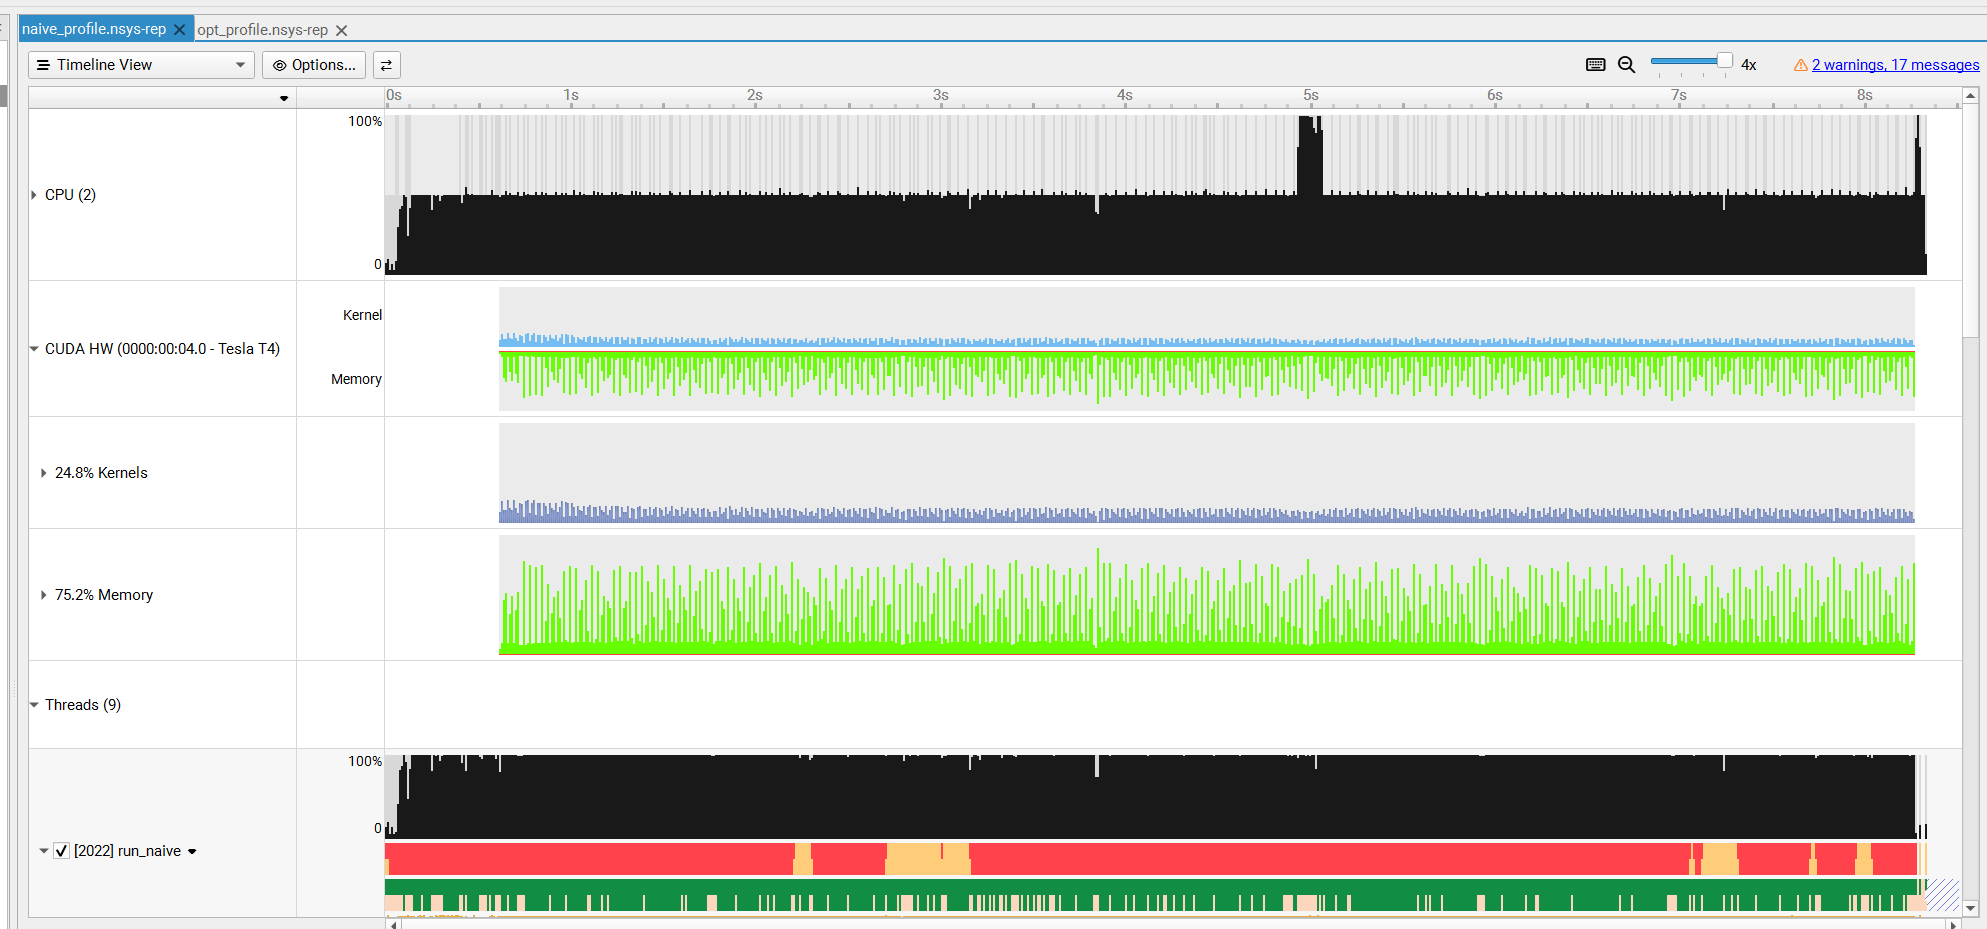

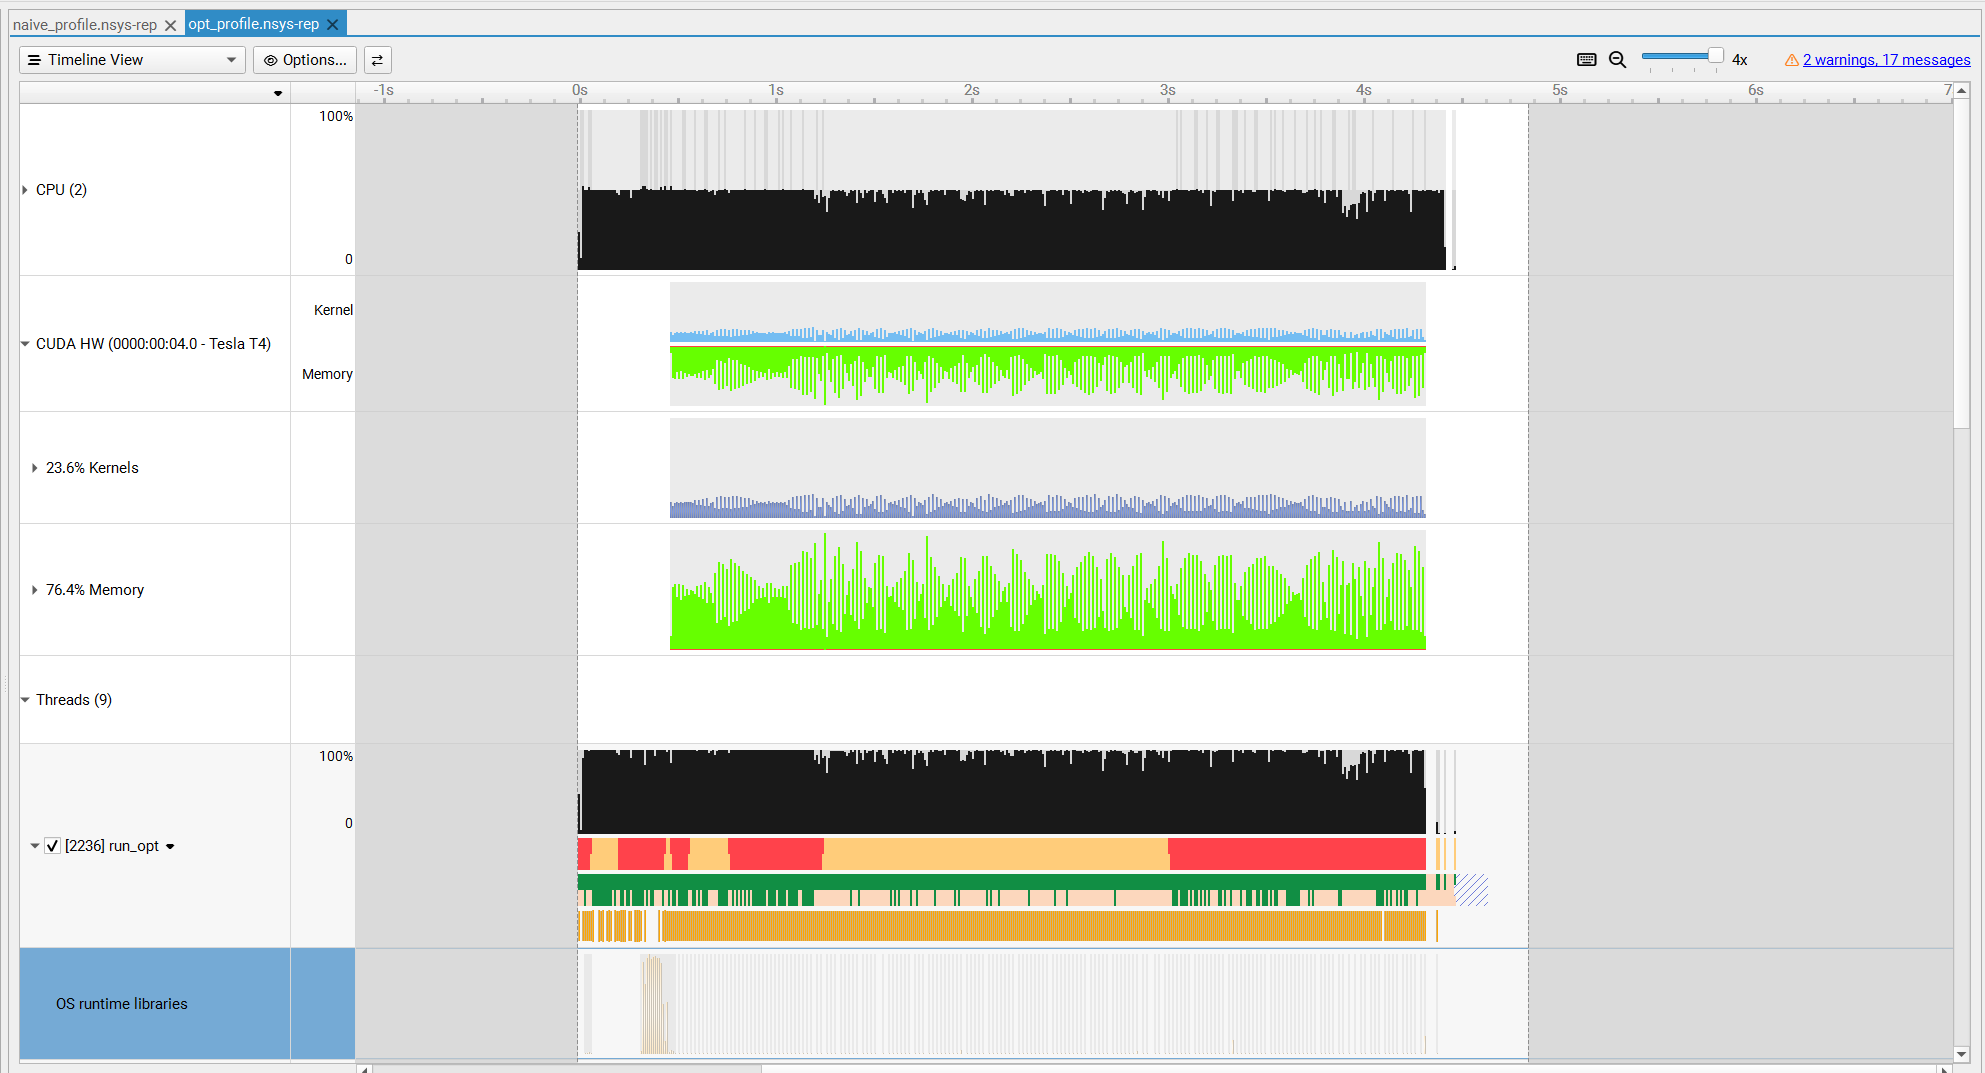

Cell 10 (Correctness Verification)
By default, llama2.c uses random sampling, which causes different runs to generate different stories and token lengths. To rigorously verify the correctness of our GPU implementations, we set the temperature parameter to zero (-t 0.0) to enforce deterministic greedy decoding. As shown in the output below, the CPU baseline, naive GPU, and optimized GPU versions all produce the exact same story word-for-word and trigger the matmul function exactly 9,546 times. This confirms that our CUDA kernel and persistent memory optimization maintain numerical accuracy, while also providing a direct apples-to-apples throughput comparison (45.15 tok/s on CPU, 31.78 tok/s on naive GPU, and 48.45 tok/s on optimized GPU).

In [11]:
!./run stories15M.bin -t 0.0
!./run_naive stories15M.bin -t 0.0
!./run_opt stories15M.bin -t 0.0

Once upon a time, there was a little girl named Lily. She loved to play outside in the sunshine. One day, she saw a big, red ball in the sky. It was the sun! She thought it was so pretty.
Lily wanted to play with the ball, but it was too high up in the sky. She tried to jump and reach it, but she couldn't. Then, she had an idea. She would use a stick to knock the ball down.
Lily found a stick and tried to hit the ball. But the stick was too short. She tried again and again, but she couldn't reach it. She felt sad.
Suddenly, a kind man came by and saw Lily. He asked her what was wrong. Lily told him about the ball. The man smiled and said, "I have a useful idea!" He took out a long stick and used it to knock the ball down. Lily was so happy! She thanked the man and they played together in the sunshine.
achieved tok/s: 45.148110
matmul triggered: 9546 times
Once upon a time, there was a little girl named Lily. She loved to play outside in the sunshine. One day, she saw a big, red ball in